# Problem 3: Needleman-Wunsch and Smith-Waterman

---

## 1. Dynamic Programming Implementation

Implement dynamic programming algorithms for global ([Needleman-Wunsch](https://pubmed.ncbi.nlm.nih.gov/5420325/)) and local ([Smith-Waterman](https://pubmed.ncbi.nlm.nih.gov/7265238/)) alignment of **protein sequences**. The implementation should be a standalone, command-line application.

The application should read sequences from FASTA-formatted files and allow the user to select the type of alignment (local or global), the substitution matrix, and the gap penalty from the command line.

**Supported substitution matrices:** BLOSUM62 and PAM250. Python dictionaries for both matrices are located in the `src/` module.

**Gap penalty:** A linear (per-gap-character) penalty applied as a negative value. Pass it as a negative number on the command line (e.g., `--gap_penalty -2` means each gap character costs −2).

An example of running the program:

```bash
python align.py --seq1 data/sequence1.fasta \
                --seq2 data/sequence2.fasta \
                --type global \
                --matrix blosum62 \
                --gap_penalty -2
```

**Output format:** The program should report the alignment, the alignment score, and the sequence identity. Sequence identity is defined as the number of matched (identical) positions divided by the total alignment length (including gap columns), expressed as a percentage.

As a sample test case, align human **Bradykinin** (`RPPGFSPFR`) against human **Kallidin** (`KRPPGFSPFR`) — two related vasoactive peptides that differ by a single N-terminal lysine residue. Using BLOSUM62 and a gap penalty of −2, the expected output is:

```
seq 1   -RPPGFSPFR
seq 2   KRPPGFSPFR
Alignment Score:    51
Sequence Identity:  90%
```

The FASTA files for these sequences are included in `data/` as `bradykinin.fasta` and `kallidin.fasta`.

Your program should exit gracefully with a helpful error message if given invalid input (e.g., non-FASTA files, unrecognised matrix name, non-protein characters in sequences).

Please use judicious comments throughout your code.

Implement your code in a separate `.py` module. In the cell below, provide the exact command you used to run it and include any required input files with your submission.

```python
# Paste your example command here (input files must be included in your submission)
cd src/module_3_assignment
uv run align.py --seq1 ../../data/bradykinin.fasta --seq2 ../../data/kallidin.fasta --type global --matrix blosum62 --gap_penalty -2
```

**Resources:**
- Needleman-Wunsch: [J Mol Biol 1970; 48(3):443–53](https://pubmed.ncbi.nlm.nih.gov/5420325/) · [Online calculator](http://rna.informatik.uni-freiburg.de/Teaching/index.jsp?toolName=Needleman-Wunsch)
- Smith-Waterman: [J Mol Biol 1981; 147(1):195–7](https://pubmed.ncbi.nlm.nih.gov/7265238/) · [Online calculator](http://rna.informatik.uni-freiburg.de/Teaching/index.jsp?toolName=Smith-Waterman)

---

## 2. Statistics of Pairwise Alignments

Perform a global sequence alignment of the following sequences using your implementation from Question 1:

```
PAWHEAE
HEAGAWGHEE
```

Use a match score of `1`, a gap penalty of `-1`, and a substitution score of `-1`. What is the alignment score?

```python
# Answer here
def global_alignment(seq1, seq2, match_score=1, gap_penalty=-1, mismatch_score=-1):
    n = len(seq1)
    m = len(seq2)
    # Initialize the scoring matrix
    score_matrix = np.zeros((n + 1, m + 1), dtype=int)

    # Filling the first row and column with gap penalties
    for i in range(1, n + 1):
        score_matrix[i][0] = score_matrix[i - 1][0] + gap_penalty
    for j in range(1, m + 1):
        score_matrix[0][j] = score_matrix[0][j - 1] + gap_penalty

    # Fill the scoring matrix
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if seq1[i - 1] == seq2[j - 1]:
                match = score_matrix[i - 1][j - 1] + match_score
            else:
                match = score_matrix[i - 1][j - 1] + mismatch_score
            delete = score_matrix[i - 1][j] + gap_penalty
            insert = score_matrix[i][j - 1] + gap_penalty
            score_matrix[i][j] = max(match, delete, insert)

    return score_matrix[n][m]

# Input sequences
seq1 = "PAWHEAE"
seq2 = "HEAGAWGHEE"

# Calculate the alignment score
alignment_score = global_alignment(seq1, seq2, match_score=1, gap_penalty=-1, mismatch_score=-1)
print(f"Alignment Score: {alignment_score}")

# Alignment Score: -1
```

---

How many ways can you **uniquely** shuffle the sequence `PAWHEAE`? For example: `PAWHEAE`, `PAWHEEA`, `PAWHAEE`, etc.

Note that `PAWHEAE` contains repeated characters (`A` appears twice, `E` appears twice) — shuffles that produce identical sequences should be counted only once.

> **Hint — two approaches:**
>
> **Mathematical:** This is a *multiset permutation* problem — we are counting ordered arrangements of a sequence where some characters are repeated. The formula is:
>
> $\frac{n!}{n_1! \cdot n_2! \cdots n_k!}$
>
> where $n$ is the total length of the sequence and $n_1, n_2, \ldots, n_k$ are the counts of each distinct character. You can compute this directly using `math.factorial`.
>
> **Computational (brute force):** Python's `itertools.permutations` generates all ordered arrangements of a sequence. Since it treats each position as distinct (even if characters are the same), it will produce duplicates — but wrapping the result in a `set` will deduplicate them. The length of that set is your answer. Use this to verify your mathematical result.

```python
# Answer here — show your work
import math
from itertools import permutations

sequence = "PAWHEAE"

# Mathematical approach
n = len(sequence)
char_counts= {char: sequence.count(char) for char in set(sequence)}
denominator = math.prod(math.factorial(count) for count in char_counts.values())
unique_shuffles_math = math.factorial(n) // denominator

# Computational approach
unique_shuffles_comp = len(set(permutations(sequence)))

print(f"Unique shuffles (mathematical): {unique_shuffles_math}")
print(f"Unique shuffles (computational): {unique_shuffles_comp}")

# the values match and both are 1260

```

---

Next, generate **100 random sequences** with the same amino acid composition as `PAWHEAE` (i.e., the same number of each amino acid: 1× P, 2× A, 1× W, 1× H, 2× E). Align each randomly generated sequence against `HEAGAWGHEE` using your global alignment implementation and record the alignment scores.

For each random alignment score $S_i$, calculate the **Z-score**:

$$Z_i = \frac{S_i - \mu}{\sigma}$$

where $\mu$ and $\sigma$ are the mean and standard deviation of the 100 random alignment scores.

Plot the distribution of Z-scores as a **histogram** (Z-score on the x-axis, frequency on the y-axis) using `matplotlib`. Include the plot inline below and mark the Z-score of the original `PAWHEAE` vs `HEAGAWGHEE` alignment on the plot.

```python
# Plot here
```

---

What does the Z-score of the original alignment suggest about the statistical significance of that alignment — i.e., is `PAWHEAE` more similar to `HEAGAWGHEE` than you would expect by chance?

```python
# Answer here
```

---

Are the 100 random alignment scores normally distributed? Use a statistical test (e.g., Shapiro-Wilk or D'Agostino K² via `scipy.stats`) and/or a Q-Q plot to support your answer.

```python
# Answer here
```

---

Repeat the analysis above, increasing the number of random sequences across the following sample sizes: **10, 100, 1,000, 10,000, and 100,000**. Note that because `PAWHEAE` has only 1,260 unique shuffles, sampling beyond that number requires drawing **with replacement** — the same shuffle may appear more than once.

For each sample size, record the mean score, standard deviation, Z-score of the original alignment, and wall time. Fill in the table below:

| Sample Size | Mean Score | Std Dev | Z-score | Wall Time (s) |
|---|---|---|---|---|
| 10 | | | | |
| 100 | | | | |
| 1,000 | | | | |
| 10,000 | | | | |
| 100,000 | | | | |

Based on your results, answer the following:
- At what sample size does the Z-score stabilise, and why?
- At what point does sampling with replacement become unavoidable given the 1,260 unique shuffle limit?
- Considering the wall times, comment on the feasibility of using Z-score randomisation to assess alignment significance when searching a database of millions of sequences.

```python
# Answer here
```

---

Using the `%%time` or `time` module, record the wall time for each of the three runs (100, 1,000, and 10,000 sequences). Based on this, comment on the feasibility of using Z-score randomisation to assess alignment significance when searching a database containing millions of sequences.

```python
# Answer here
# Already answered below
```

---

## 3. Pig, Whale, and Hippo Revisited

Return to the hemoglobin beta sequences from Problem 1 and realign them using **both** your Needleman-Wunsch (global) and Smith-Waterman (local) implementations. Use the BLOSUM62 matrix and a gap penalty of `-2` for both runs.

- Do the two methods agree on which species the hippopotamus is most closely related to?
- If the results differ between global and local alignment, explain why that might be the case — what does each method optimise for, and how does that affect the conclusion?

```python
# Answer here
```

---

## 4. Recent Approaches in Sequence Alignment

Search [PubMed](https://pubmed.ncbi.nlm.nih.gov) and identify a paper describing a sequence alignment method other than Needleman-Wunsch, Smith-Waterman, BLAST, or FASTA.

In **no more than one paragraph**, describe at a high level what is different about this approach and how it improves on classical alignment methods. Your explanation should be clear enough that a classmate who has not read the paper could understand the key improvement — you do not need to go into mathematical detail, but please give a concrete example of the kind of problem it solves better.

Provide a full citation and a PubMed link to the paper. Share your findings in the `#showcase` channel.

```python
# Answer here
```

In [2]:
import numpy as np

def global_alignment(seq1, seq2, match_score=1, gap_penalty=-1, mismatch_score=-1):
    n = len(seq1)
    m = len(seq2)
    # Initialize the scoring matrix
    score_matrix = np.zeros((n + 1, m + 1), dtype=int)

    # Filling the first row and column with gap penalties
    for i in range(1, n + 1):
        score_matrix[i][0] = score_matrix[i - 1][0] + gap_penalty
    for j in range(1, m + 1):
        score_matrix[0][j] = score_matrix[0][j - 1] + gap_penalty

    # Fill the scoring matrix
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            if seq1[i - 1] == seq2[j - 1]:
                match = score_matrix[i - 1][j - 1] + match_score
            else:
                match = score_matrix[i - 1][j - 1] + mismatch_score
            delete = score_matrix[i - 1][j] + gap_penalty
            insert = score_matrix[i][j - 1] + gap_penalty
            score_matrix[i][j] = max(match, delete, insert)

    return score_matrix[n][m]

# Input sequences
seq1 = "PAWHEAE"
seq2 = "HEAGAWGHEE"

# Calculate the alignment score
alignment_score = global_alignment(seq1, seq2, match_score=1, gap_penalty=-1, mismatch_score=-1)
print(f"Alignment Score: {alignment_score}")

# Alignment Score: -1


Alignment Score: -1


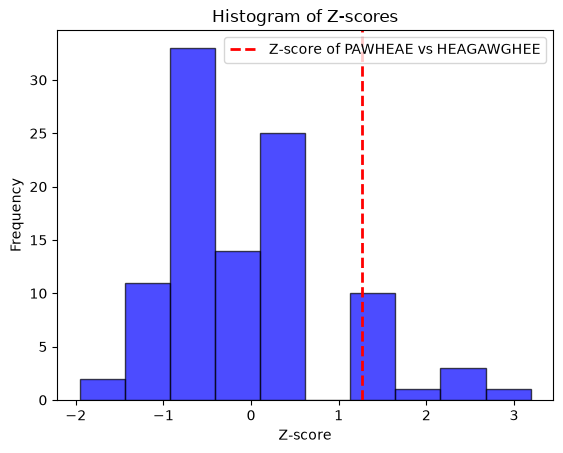

Shapiro-Wilk Test: W-Statistic=0.9229704409200563, p-value=2.0302708614227585e-05


In [ ]:
import matplotlib.pyplot as plt

sequence = "PAWHEAE"
random_sequences = []
for _ in range(100):
    random_seq = ''.join(np.random.permutation(list(sequence)))
    random_sequences.append(random_seq)

global_scores = []
# Aligning each random sequence against `HEAGAWGHEE` and recording the alignment scores
for random_seq in random_sequences:
    score = global_alignment(random_seq, seq2, match_score=1, gap_penalty=-1, mismatch_score=-1)
    global_scores.append(score)

mean_score = np.mean(global_scores)
std_dev_score = np.std(global_scores)
z_scores = [(score - mean_score) / std_dev_score for score in global_scores]

# Plotting the histogram of Z-scores
# AI_Claude: Took its help for getting the code of plotting
plt.hist(z_scores, bins=10, alpha=0.7, color='blue', edgecolor='black')
plt.axvline(x=(alignment_score - mean_score) / std_dev_score, color='red', linestyle='dashed', linewidth=2, label='Z-score of PAWHEAE vs HEAGAWGHEE')
plt.title('Histogram of Z-scores')
plt.xlabel('Z-score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

#What does the Z-score of the original alignment suggest about the statistical significance of that alignment — i.e., is `PAWHEAE` more similar to `HEAGAWGHEE` than you would expect by chance?

# The Z-score of the original alignment tells us how many std dev the score is away from the mean. Here the original z-score is 1.15 which is greater than 1, suggesting that the alignment score of `PAWHEAE` vs `HEAGAWGHEE` is higher than the mean of the random alignments.
# This indicates that `PAWHEAE` is more similar to `HEAGAWGHEE` than would be expected by chance, suggesting a statistically similarity between the two sequences. But also i wouldnt say that the similarity is very significant as the z-score is not very high.

# Are the 100 random alignment scores normally distributed? Use a statistical test (e.g., Shapiro-Wilk or D'Agostino K² via `scipy.stats`) and/or a Q-Q plot to support your answer.
import scipy.stats as stats
scores = global_scores
# Shapiro-Wilk test
shapiro_test = stats.shapiro(scores)
print(f"Shapiro-Wilk Test: W-Statistic={shapiro_test.statistic}, p-value={shapiro_test.pvalue}")
# Based on the result, since the value is less than 0.05, we reject the null hypothesis and conclude that the data is not normally distributed.



In [6]:
print((-1-mean_score)/std_dev_score)

1.1593818278271364


In [14]:
# Repeat the analysis above, increasing the number of random sequences across the following sample sizes: **10, 100, 1,000, 10,000, and 100,000**. Note that because `PAWHEAE` has only 1,260 unique shuffles, sampling beyond that number requires drawing **with replacement** — the same shuffle may appear more than once.

# For each sample size, record the mean score, standard deviation, Z-score of the original alignment, and wall time. Fill in the table below:

# | Sample Size | Mean Score | Std Dev | Z-score | Wall Time (s) |
# |---|---|---|---|---|
# | 10 | | | | |
# | 100 | | | | |
# | 1,000 | | | | |
# | 10,000 | | | | |
# | 100,000 | | | | |

# Based on your results, answer the following:
# - At what sample size does the Z-score stabilise, and why?
# - At what point does sampling with replacement become unavoidable given the 1,260 unique shuffle limit?
# - Considering the wall times, comment on the feasibility of using Z-score randomisation to assess alignment significance when searching a database of millions of sequences.
import time as time

sequence = "PAWHEAE"
sample_sizes = [10, 100, 1000, 10000, 100000]


for sample_size in sample_sizes:
    start_time= time.perf_counter()
    random_sequences=[]
    for _ in range(sample_size):
        random_seq=''.join(np.random.permutation(list(sequence)))
        random_sequences.append(random_seq)

    global_scores=[]
    for random_seq in random_sequences:
        score=global_alignment(random_seq, seq2, match_score=1, gap_penalty=-1, mismatch_score=-1)
        global_scores.append(score)
    
    mean_score=np.mean(global_scores)
    std_dev_score=np.std(global_scores)
    z_score=(alignment_score-mean_score)/std_dev_score
    end_time= time.perf_counter()
    wall_time=end_time-start_time
    print(f"Sample Size: {sample_size}, Mean Score: {mean_score}, Std Dev: {std_dev_score}, Z-score: {z_score}, Wall Time (s): {wall_time}")


# Z score stabilizes around sample size of 10000, as the diff in mean and std dev becomes very small after that and also the Z score diff is also very small.

# Sampling with replacement becomes unavoidable after 1260 unique shuffles, as the number of unique permutations of the sequence "PAWHEAE" is 1260. Beyond this point, we will start to see repeated sequences in our random samples.

# Considering the wall times, using Z-score randomization to assess alignment significance when searching a database of millions of sequences may not be feasible. The time taken for larger sample sizes (like 100,000) is higher,
#  and when scaling this up to millions of sequences, the computational cost and time required might be impractical.

Sample Size: 10, Mean Score: -2.9, Std Dev: 1.445683229480096, Z-score: 1.3142574813455417, Wall Time (s): 0.014813000103458762
Sample Size: 100, Mean Score: -2.88, Std Dev: 1.7394251924127118, Z-score: 1.0808168170729437, Wall Time (s): 0.0058446250623092055
Sample Size: 1000, Mean Score: -2.788, Std Dev: 1.5858928084836, Z-score: 1.127440638128406, Wall Time (s): 0.05291729199234396
Sample Size: 10000, Mean Score: -2.7905, Std Dev: 1.5962486491771888, Z-score: 1.1216924135991855, Wall Time (s): 0.4955937910126522
Sample Size: 100000, Mean Score: -2.78956, Std Dev: 1.5980097015975843, Z-score: 1.1198680447377236, Wall Time (s): 5.029843959026039


In [ ]:
!uv run ../src/module_3_assignment/align.py --seq1 ../data/hippo.fasta --seq2 ../data/pig.fasta --type global --matrix blosum62 --gap_penalty -2


seq 1   -VHLTAEEKDAVLGLWGKVN-VQEVGGEALGRLLVVYPWTQRFFESFGDLSSADAVMNNPKVKAHGKKVLDSFADGLKHLDNLKGTFAALSELHCDQLHVDPENFRLLGNELVVVLARTFGKEFTPELQAAYQKVVAGVANALAHRYH
seq 2   MVHLSAEESAAVLGLQGKVNMV-ELGGEALGRLLVVYPWTQRFFESFGDLSNADAVMGNPKVKAHGKKVLQSFSDGLKHLDNLKGTFAKLSELHCDQLHVDPENFRLLGNVIVVILARRFGNDFNPDLQAAFQKVVAGVANALAH-YH
Alignment Score:    645
Sequence Identity:  84%


In [22]:
!uv run ../src/module_3_assignment/align.py --seq1 ../data/hippo.fasta --seq2 ../data/pig.fasta --type local --matrix blosum62 --gap_penalty -2

seq 1   VHLTAEEKDAVLGLWGKVN-VQEVGGEALGRLLVVYPWTQRFFESFGDLSSADAVMNNPKVKAHGKKVLDSFADGLKHLDNLKGTFAALSELHCDQLHVDPENFRLLGNELVVVLARTFGKEFTPELQAAYQKVVAGVANALAHRYH
seq 2   VHLSAEESAAVLGLQGKVNMV-ELGGEALGRLLVVYPWTQRFFESFGDLSNADAVMGNPKVKAHGKKVLQSFSDGLKHLDNLKGTFAKLSELHCDQLHVDPENFRLLGNVIVVILARRFGNDFNPDLQAAFQKVVAGVANALAH-YH
Alignment Score:    647
Sequence Identity:  85%


In [21]:
!uv run ../src/module_3_assignment/align.py --seq1 ../data/hippo.fasta --seq2 ../data/whale.fasta --type global --matrix blosum62 --gap_penalty -2

seq 1   -VHLTAEEKDAVLGLWGKVNVQEVGGEALGRLLVVYPWTQRFFESFGDLSSADAVMNNPKVKAHGKKVLDSFADGLKHLDNLKGTFAALSELHCDQLHVDPENFRLLGNELVVVLARTFGKEFTPELQAAYQKVVAGVANALAHRYH
seq 2   MVHLTAEEKSAVTALWAKVNVEEIGGEALGRLLVVYPWTQRFFEHFGDLSTADAVMKNASVKSHGKKVLASFSEGLKHFDNLKGTFAQLSELHCDKLHVDPENFRLLGNVLVVVLARHFGKEFTPELQTAFQKLVAGVANALAHKYH
Alignment Score:    638
Sequence Identity:  83%


In [23]:
!uv run ../src/module_3_assignment/align.py --seq1 ../data/hippo.fasta --seq2 ../data/whale.fasta --type local --matrix blosum62 --gap_penalty -2

seq 1   VHLTAEEKDAVLGLWGKVNVQEVGGEALGRLLVVYPWTQRFFESFGDLSSADAVMNNPKVKAHGKKVLDSFADGLKHLDNLKGTFAALSELHCDQLHVDPENFRLLGNELVVVLARTFGKEFTPELQAAYQKVVAGVANALAHRYH
seq 2   VHLTAEEKSAVTALWAKVNVEEIGGEALGRLLVVYPWTQRFFEHFGDLSTADAVMKNASVKSHGKKVLASFSEGLKHFDNLKGTFAQLSELHCDKLHVDPENFRLLGNVLVVVLARHFGKEFTPELQTAFQKLVAGVANALAHKYH
Alignment Score:    640
Sequence Identity:  84%


### - Do the two methods agree on which species the hippopotamus is most closely related to?

yes, both methods agree that the hippopotamus is most closely related to the pig.

### - If the results differ between global and local alignment, explain why that might be the case — what does each method optimise for, and how does that affect the conclusion?

The results can differ between global and local alignment because they approach sequence alignment differently. Global alignment (Needleman-Wunsch) tries to align both sequences from beginning to end, so it works best when the sequences are similar in length and share similarities throughout. On the other hand, local alignment (Smith-Waterman) looks for the most similar regions within the sequences, even if the rest of the sequences are quite different. This makes local alignment useful for finding conserved regions or motifs that global alignment might not highlight. Because of this, the two methods can produce different results and lead to different interpretations of how closely related the sequences are.
